
# Final Test Evaluation and Model Explainability

## Objectives
1. Evaluate the selected validation-optimized weighted ensemble on the untouched test set.
2. Compare it with the tuned CatBoost model as an individual-model benchmark.
3. Report MAE, RMSE, and R².
4. Explain CatBoost predictions using SHAP.
5. Examine feature effects using Partial Dependence Plots (PDP) and Accumulated Local Effects (ALE).

## Evaluation Protocol
- Reuse the fixed train, validation, and test assignments.
- Load fitted models and ensemble weights from previous notebooks.
- Do not tune models, change weights, or select a model based on test performance.
- Treat test metrics as the final generalization assessment.


In [1]:

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.inspection import PartialDependenceDisplay

warnings.filterwarnings("ignore", category=FutureWarning)

current_dir = Path.cwd()
possible_roots = [current_dir, current_dir.parent]

PROJECT_ROOT = next(
    (
        path for path in possible_roots
        if (path / "data" / "Processed_527_datapoints.csv").exists()
        and (path / "artifacts" / "feature_config.json").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root.")

DATA_PATH = PROJECT_ROOT / "data" / "Processed_527_datapoints.csv"
SPLIT_PATH = PROJECT_ROOT / "artifacts" / "splits" / "split_assignments.csv"
FEATURE_CONFIG_PATH = PROJECT_ROOT / "artifacts" / "feature_config.json"
TUNED_MODEL_DIR = PROJECT_ROOT / "artifacts" / "tuned_models"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURE_DIR = RESULTS_DIR / "figures"

for directory in [RESULTS_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)


Project root: /Users/divyakandlakuti/Desktop/interpretable-co2-adsorption-ml


In [2]:

df = pd.read_csv(DATA_PATH)
split_assignments = pd.read_csv(SPLIT_PATH)

with open(FEATURE_CONFIG_PATH, "r", encoding="utf-8") as file:
    feature_config = json.load(file)

TARGET_COLUMN = feature_config["target"]
FEATURE_COLUMNS = feature_config["features"]

df = df.drop_duplicates().reset_index(drop=True)

if "row_id" not in df.columns:
    df.insert(0, "row_id", np.arange(len(df)))

if df["row_id"].duplicated().any():
    raise ValueError("Duplicate row_id values in the dataset.")

if split_assignments["row_id"].duplicated().any():
    raise ValueError("Duplicate row_id values in the split file.")

data = df.merge(
    split_assignments[["row_id", "split"]],
    on="row_id",
    how="inner",
    validate="one_to_one",
)

if len(data) != len(split_assignments):
    raise ValueError(
        "The dataset and split assignments do not match. "
        "Stop and inspect row_id alignment."
    )

if data[TARGET_COLUMN].isna().any():
    raise ValueError("Target contains missing values.")

train_df = data[data["split"] == "train"].copy()
val_df = data[data["split"] == "validation"].copy()
test_df = data[data["split"] == "test"].copy()

X_train = train_df[FEATURE_COLUMNS]
X_val = val_df[FEATURE_COLUMNS]
X_test = test_df[FEATURE_COLUMNS]

y_train = train_df[TARGET_COLUMN].to_numpy()
y_val = val_df[TARGET_COLUMN].to_numpy()
y_test = test_df[TARGET_COLUMN].to_numpy()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("Features:", len(FEATURE_COLUMNS))
print("Target:", TARGET_COLUMN)

assert len(test_df) > 0


Training rows: 336
Validation rows: 84
Test rows: 106
Features: 10
Target: CO2 uptake (mmol/g)


In [3]:

MODEL_FILES = {
    "Random Forest": "tuned_random_forest.joblib",
    "Extra Trees": "tuned_extra_trees.joblib",
    "Gradient Boosting": "tuned_gradient_boosting.joblib",
    "XGBoost": "tuned_xgboost.joblib",
    "LightGBM": "tuned_lightgbm.joblib",
    "CatBoost": "tuned_catboost.joblib",
}

tuned_pipelines = {}

for model_name, filename in MODEL_FILES.items():
    model_path = TUNED_MODEL_DIR / filename

    if not model_path.exists():
        raise FileNotFoundError(
            f"Missing tuned model: {model_path}. "
            "Complete Notebook 06 first."
        )

    tuned_pipelines[model_name] = joblib.load(model_path)

weights_path = RESULTS_DIR / "ensemble_weights.csv"

if not weights_path.exists():
    raise FileNotFoundError(
        "Missing ensemble_weights.csv. Complete Notebook 07 first."
    )

weights_df = pd.read_csv(weights_path)

required_columns = {"Model", "Validation_Optimized_Weight"}
if not required_columns.issubset(weights_df.columns):
    raise ValueError("The saved ensemble weights file has unexpected columns.")

weight_map = dict(zip(
    weights_df["Model"],
    weights_df["Validation_Optimized_Weight"],
))

if set(weight_map) != set(MODEL_FILES):
    raise ValueError("Ensemble weights do not match the six tuned models.")

ensemble_weights = np.array([
    weight_map[name] for name in MODEL_FILES
], dtype=float)

if not np.isfinite(ensemble_weights).all():
    raise ValueError("Ensemble weights contain invalid values.")

if (ensemble_weights < -1e-10).any():
    raise ValueError("Ensemble weights must be non-negative.")

if not np.isclose(ensemble_weights.sum(), 1.0, atol=1e-6):
    raise ValueError("Ensemble weights must sum to one.")

print("All six tuned models loaded.")
print("Saved validation-optimized ensemble weights:")
display(weights_df.round(5))


All six tuned models loaded.
Saved validation-optimized ensemble weights:


,Model,Simple_Average_Weight,Validation_Optimized_Weight,Entropy_TOPSIS_Weight
0,Random Forest,0.16667,0.00000,0.00000
1,Extra Trees,0.16667,0.00000,0.05320
2,Gradient Boosting,0.16667,0.00000,0.12521
3,XGBoost,0.16667,0.17702,0.22920
4,LightGBM,0.16667,0.27657,0.28307
5,CatBoost,0.16667,0.54642,0.30931


In [4]:

test_predictions_by_model = {}

for model_name, pipeline in tuned_pipelines.items():
    predictions = pipeline.predict(X_test)

    if not np.isfinite(predictions).all():
        raise ValueError(f"{model_name} produced invalid test predictions.")

    test_predictions_by_model[model_name] = predictions

test_prediction_matrix = np.column_stack([
    test_predictions_by_model[name] for name in MODEL_FILES
])

weighted_ensemble_test_predictions = (
    test_prediction_matrix @ ensemble_weights
)

catboost_test_predictions = test_predictions_by_model["CatBoost"]

print("Test predictions generated.")
print("Ensemble weights sum:", ensemble_weights.sum())
print("Test rows evaluated:", len(y_test))


Test predictions generated.
Ensemble weights sum: 1.0
Test rows evaluated: 106


In [5]:

def evaluate_regression(actual, predicted):
    return {
        "MAE": float(mean_absolute_error(actual, predicted)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "R2": float(r2_score(actual, predicted)),
    }

test_results = []

# Evaluate every individual tuned model for transparent comparison.
for model_name, predictions in test_predictions_by_model.items():
    test_results.append({
        "Model": model_name,
        **evaluate_regression(y_test, predictions),
    })

test_results.extend([
    {
        "Model": "Validation-Optimized Weighted Ensemble",
        **evaluate_regression(y_test, weighted_ensemble_test_predictions),
    },
])

test_comparison_df = (
    pd.DataFrame(test_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(test_comparison_df.round(4))

test_results_path = RESULTS_DIR / "final_test_results.csv"
test_comparison_df.to_csv(test_results_path, index=False)

print("Saved:", test_results_path.relative_to(PROJECT_ROOT))


,Model,MAE,RMSE,R2
0,Validation-Optimized Weighted Ensemble,0.5220,0.7064,0.8173
1,LightGBM,0.5211,0.7104,0.8152
2,XGBoost,0.5234,0.7151,0.8127
3,Gradient Boosting,0.5289,0.7218,0.8092
4,CatBoost,0.5445,0.7355,0.8019
5,Random Forest,0.5899,0.7992,0.7661
6,Extra Trees,0.5952,0.8024,0.7643


Saved: results/final_test_results.csv


In [6]:

test_prediction_output = pd.DataFrame({
    "row_id": test_df["row_id"].to_numpy(),
    "Actual_CO2_uptake": y_test,
    "Weighted_Ensemble_Prediction": weighted_ensemble_test_predictions,
    "CatBoost_Prediction": catboost_test_predictions,
})

for model_name, predictions in test_predictions_by_model.items():
    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    test_prediction_output[f"{safe_name}_prediction"] = predictions

test_predictions_path = RESULTS_DIR / "final_test_predictions.csv"
test_prediction_output.to_csv(test_predictions_path, index=False)

display(test_prediction_output.head())
print("Saved:", test_predictions_path.relative_to(PROJECT_ROOT))


,row_id,Actual_CO2_uptake,Weighted_Ensemble_Prediction,CatBoost_Prediction,random_forest_prediction,extra_trees_prediction,gradient_boosting_prediction,xgboost_prediction,lightgbm_prediction,catboost_prediction
0,0,2.625000,2.922638,2.939862,2.840022,2.941824,2.921013,2.547797,3.128529,2.939862
1,2,2.920455,3.166330,3.162074,2.866865,3.062866,3.254292,2.811960,3.401555,3.162074
2,6,3.450000,2.560011,2.631707,2.463327,2.971836,2.626968,2.456153,2.484837,2.631707
3,9,4.540000,3.755270,3.761286,3.477538,3.481333,3.747573,3.858414,3.677364,3.761286
4,10,4.460000,3.403861,3.291745,3.309352,3.467999,3.450937,3.410179,3.621327,3.291745


Saved: results/final_test_predictions.csv


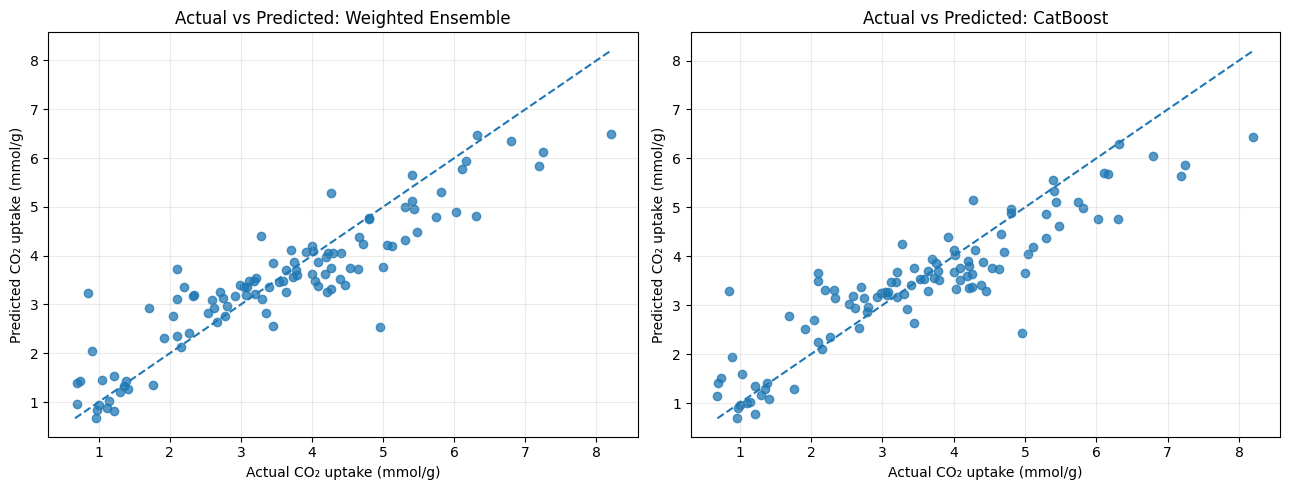

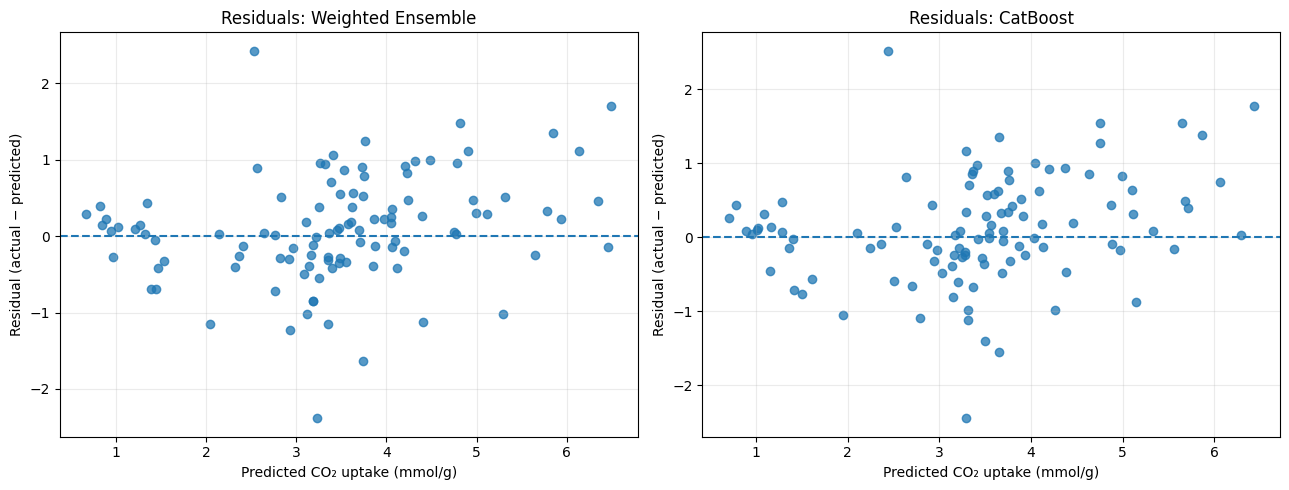

Saved: results/figures/final_test_actual_vs_predicted.png
Saved: results/figures/final_test_residuals.png


In [7]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, model_name, predictions in [
    (
        axes[0],
        "Weighted Ensemble",
        weighted_ensemble_test_predictions,
    ),
    (
        axes[1],
        "CatBoost",
        catboost_test_predictions,
    ),
]:
    ax.scatter(y_test, predictions, alpha=0.75)

    lower = min(float(y_test.min()), float(predictions.min()))
    upper = max(float(y_test.max()), float(predictions.max()))
    ax.plot([lower, upper], [lower, upper], linestyle="--")

    ax.set_title(f"Actual vs Predicted: {model_name}")
    ax.set_xlabel("Actual CO₂ uptake (mmol/g)")
    ax.set_ylabel("Predicted CO₂ uptake (mmol/g)")
    ax.grid(alpha=0.25)

fig.tight_layout()
actual_plot_path = FIGURE_DIR / "final_test_actual_vs_predicted.png"
fig.savefig(actual_plot_path, dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, model_name, predictions in [
    (
        axes[0],
        "Weighted Ensemble",
        weighted_ensemble_test_predictions,
    ),
    (
        axes[1],
        "CatBoost",
        catboost_test_predictions,
    ),
]:
    residuals = y_test - predictions
    ax.scatter(predictions, residuals, alpha=0.75)
    ax.axhline(0, linestyle="--")
    ax.set_title(f"Residuals: {model_name}")
    ax.set_xlabel("Predicted CO₂ uptake (mmol/g)")
    ax.set_ylabel("Residual (actual − predicted)")
    ax.grid(alpha=0.25)

fig.tight_layout()
residual_plot_path = FIGURE_DIR / "final_test_residuals.png"
fig.savefig(residual_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", actual_plot_path.relative_to(PROJECT_ROOT))
print("Saved:", residual_plot_path.relative_to(PROJECT_ROOT))


In [8]:

%pip install shap


  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 5.6 MB/s  0:00:00
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [shap]2/3 [shap]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:

import shap

RANDOM_STATE = 42

catboost_pipeline = tuned_pipelines["CatBoost"]
imputer = catboost_pipeline.named_steps["imputer"]
catboost_model = catboost_pipeline.named_steps["model"]

# Apply the already-fitted imputer; do not refit it.
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=FEATURE_COLUMNS,
    index=X_test.index,
)

# Limit the explanation sample if needed, while keeping it reproducible.
SHAP_SAMPLE_SIZE = min(100, len(X_test_imputed))
X_shap = X_test_imputed.sample(
    n=SHAP_SAMPLE_SIZE,
    random_state=RANDOM_STATE,
)

explainer = shap.TreeExplainer(catboost_model)
shap_values = explainer.shap_values(X_shap)

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3 and shap_values.shape[-1] == 1:
    shap_values = shap_values[:, :, 0]

print("SHAP sample rows:", len(X_shap))
print("SHAP matrix shape:", shap_values.shape)


SHAP sample rows: 100
SHAP matrix shape: (100, 10)


,Feature,Mean_Absolute_SHAP
0,Temp (°C),0.60897
1,Pressure (bar),0.54855
2,Surface Area (m2/g),0.29607
3,N (%),0.14877
4,Total Pore Volume(cm3/g),0.08510
5,H (%),0.08323
6,Micropore Volume (cm3/g),0.07863
7,O (%),0.07467
8,C (%),0.04983
9,S (%),0.02265


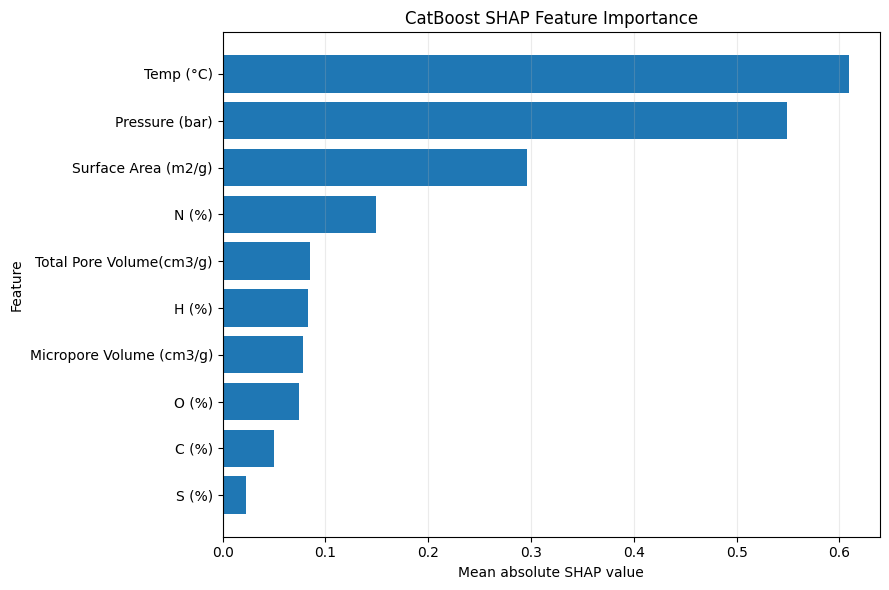

Saved: results/shap_feature_importance.csv
Saved: results/figures/shap_feature_importance.png


In [11]:

mean_absolute_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Mean_Absolute_SHAP": mean_absolute_shap,
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False,
).reset_index(drop=True)

display(shap_importance_df.round(5))

shap_importance_path = RESULTS_DIR / "shap_feature_importance.csv"
shap_importance_df.to_csv(shap_importance_path, index=False)

fig, ax = plt.subplots(figsize=(9, 6))
plot_df = shap_importance_df.sort_values("Mean_Absolute_SHAP")

ax.barh(plot_df["Feature"], plot_df["Mean_Absolute_SHAP"])
ax.set_title("CatBoost SHAP Feature Importance")
ax.set_xlabel("Mean absolute SHAP value")
ax.set_ylabel("Feature")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
shap_plot_path = FIGURE_DIR / "shap_feature_importance.png"
fig.savefig(shap_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", shap_importance_path.relative_to(PROJECT_ROOT))
print("Saved:", shap_plot_path.relative_to(PROJECT_ROOT))


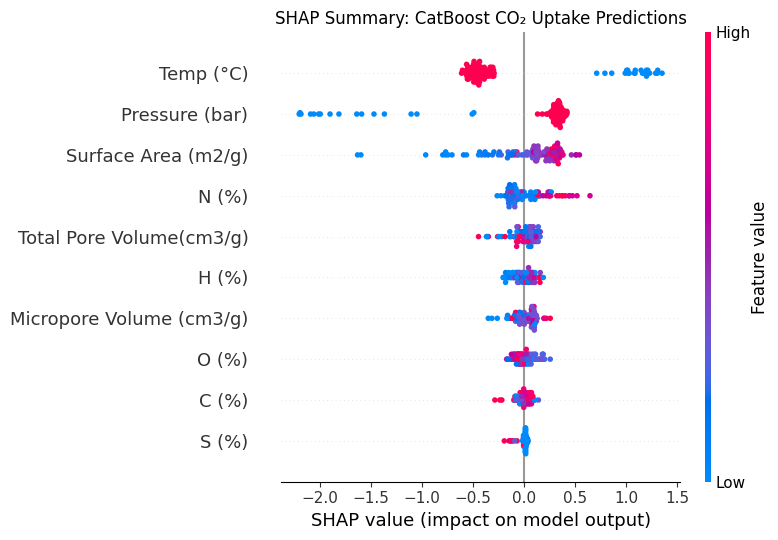

Saved: results/figures/shap_summary_plot.png


In [12]:

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=FEATURE_COLUMNS,
    show=False,
)

plt.title("SHAP Summary: CatBoost CO₂ Uptake Predictions")
plt.tight_layout()

shap_summary_path = FIGURE_DIR / "shap_summary_plot.png"
plt.savefig(shap_summary_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", shap_summary_path.relative_to(PROJECT_ROOT))


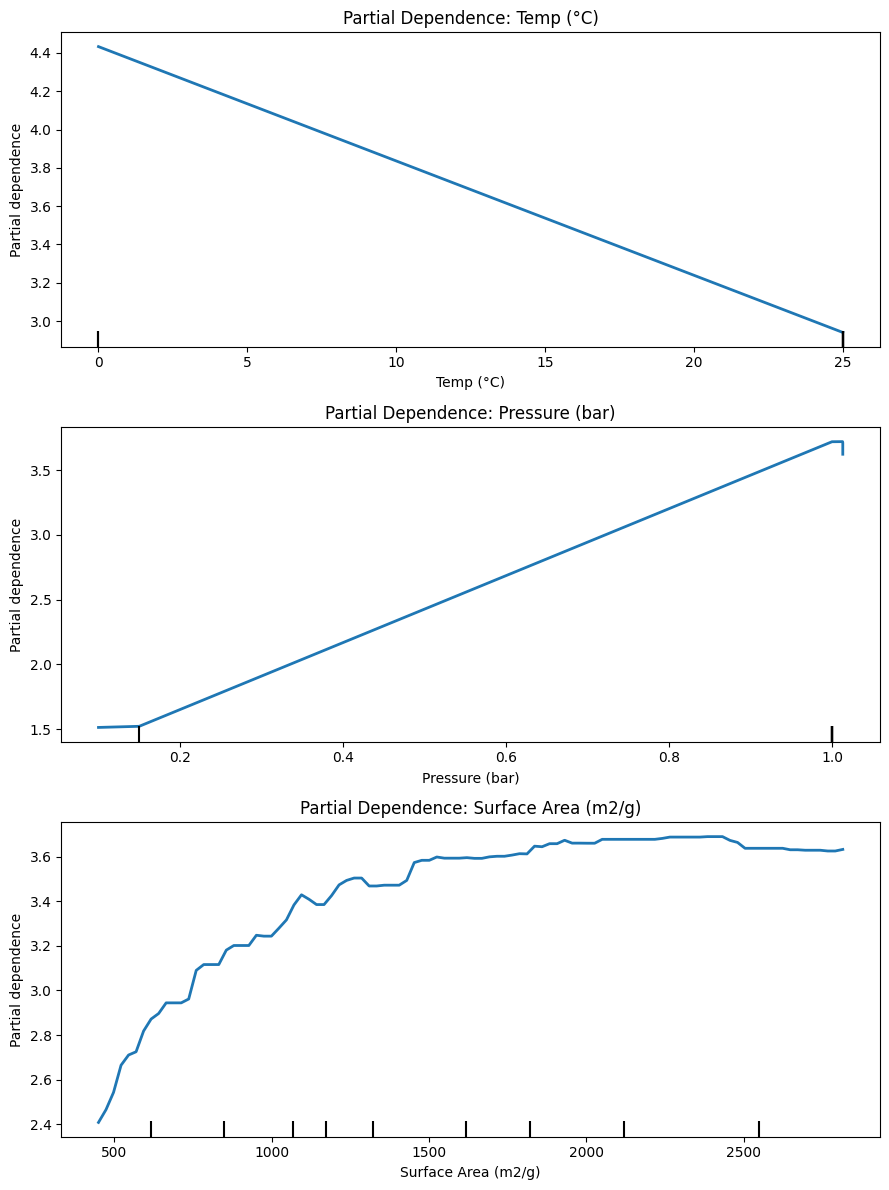

Saved: results/figures/catboost_partial_dependence.png


In [14]:

# Use training features for explanatory plots, not the held-out test set.
X_pdp = X_train.sample(
    n=min(200, len(X_train)),
    random_state=42,
).copy()

# Convert integer-valued feature columns to float for PDP compatibility.
for column in X_pdp.columns:
    if pd.api.types.is_integer_dtype(X_pdp[column]):
        X_pdp[column] = X_pdp[column].astype(float)

top_features = shap_importance_df.head(3)["Feature"].tolist()

fig, axes = plt.subplots(
    len(top_features),
    1,
    figsize=(9, 4 * len(top_features)),
)
axes = np.atleast_1d(axes)

for axis, feature in zip(axes, top_features):
    PartialDependenceDisplay.from_estimator(
        catboost_pipeline,
        X_pdp,
        features=[feature],
        kind="average",
        ax=axis,
        line_kw={"linewidth": 2},
    )

    axis.set_title(f"Partial Dependence: {feature}")
    axis.set_ylabel("Predicted CO₂ uptake (mmol/g)")
    axis.grid(alpha=0.25)

fig.tight_layout()

pdp_path = FIGURE_DIR / "catboost_partial_dependence.png"
fig.savefig(pdp_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", pdp_path.relative_to(PROJECT_ROOT))


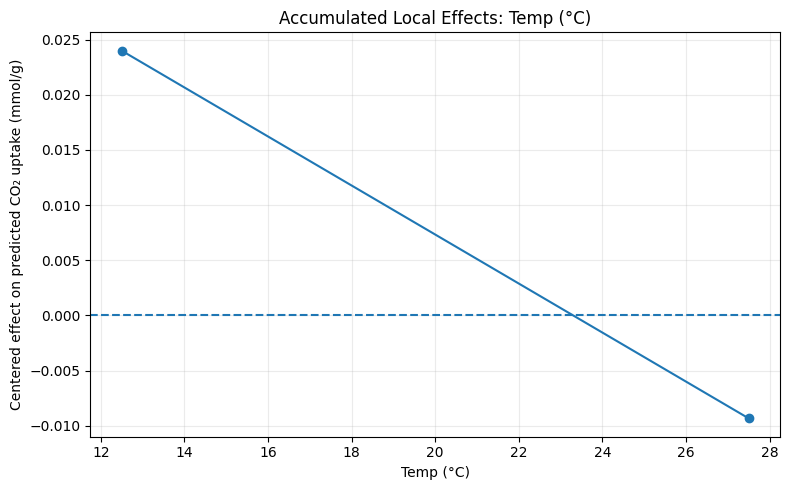

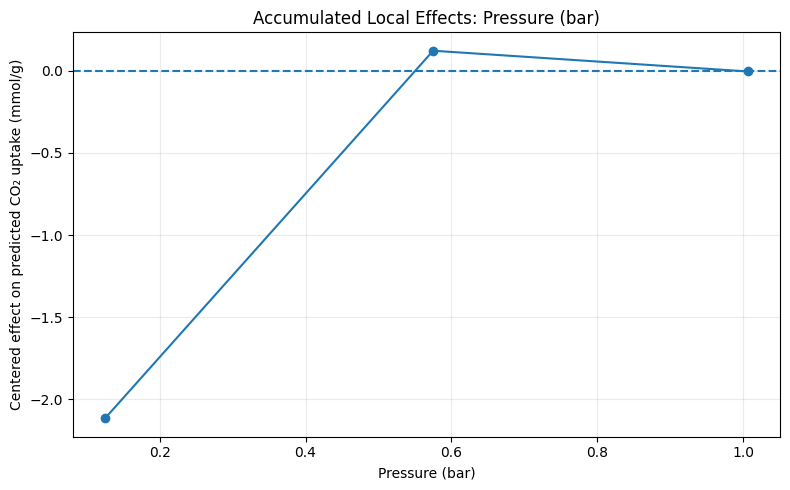

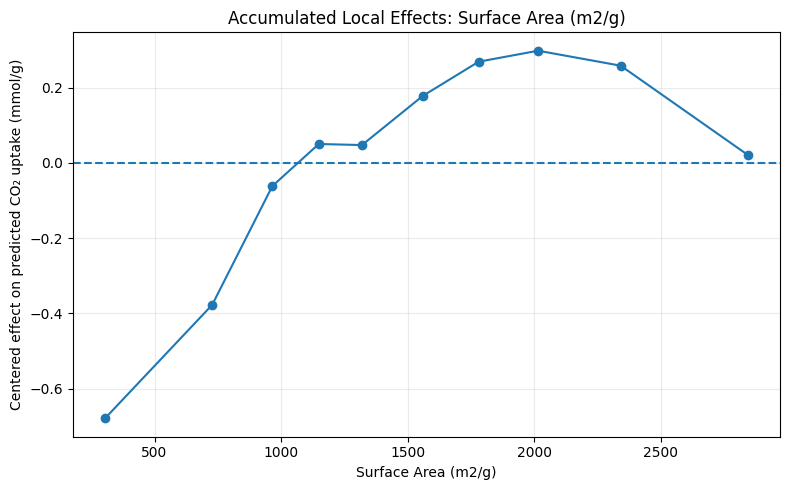

ALE calculations completed for: ['Temp (°C)', 'Pressure (bar)', 'Surface Area (m2/g)']


In [15]:

def calculate_ale(model, X, feature, bins=10):
    """
    Calculate first-order ALE for a fitted regression pipeline.

    Quantile bins are used to respect the observed feature distribution.
    Effects are centered to have approximately zero sample-weighted mean.
    """
    X = X.copy()
    feature_values = X[feature].dropna()

    edges = np.unique(
        np.quantile(feature_values, np.linspace(0, 1, bins + 1))
    )

    if len(edges) < 3:
        raise ValueError(
            f"Not enough distinct values to calculate ALE for {feature}."
        )

    # Include the largest observed value in the last bin.
    bin_indices = np.searchsorted(
        edges[1:-1],
        X[feature].to_numpy(),
        side="right",
    )

    local_effects = []
    counts = []
    interval_centers = []

    for bin_index in range(len(edges) - 1):
        mask = bin_indices == bin_index
        count = int(mask.sum())

        if count == 0:
            local_effects.append(0.0)
            counts.append(0)
            interval_centers.append(
                (edges[bin_index] + edges[bin_index + 1]) / 2
            )
            continue

        X_low = X.loc[mask].copy()
        X_high = X.loc[mask].copy()

        X_low[feature] = edges[bin_index]
        X_high[feature] = edges[bin_index + 1]

        pred_low = model.predict(X_low)
        pred_high = model.predict(X_high)

        local_effect = float(np.mean(pred_high - pred_low))

        local_effects.append(local_effect)
        counts.append(count)
        interval_centers.append(
            (edges[bin_index] + edges[bin_index + 1]) / 2
        )

    accumulated = np.cumsum(local_effects)
    counts = np.asarray(counts, dtype=float)

    if counts.sum() == 0:
        raise ValueError(f"No usable observations for {feature}.")

    # Center the ALE curve using sample-count-weighted mean.
    weighted_mean = np.average(accumulated, weights=counts)
    centered_ale = accumulated - weighted_mean

    return pd.DataFrame({
        "Feature_Value": interval_centers,
        "ALE": centered_ale,
        "Bin_Count": counts.astype(int),
    })


ale_results = {}

for feature in top_features:
    ale_df = calculate_ale(
        catboost_pipeline,
        X_train,
        feature,
        bins=10,
    )
    ale_results[feature] = ale_df

    safe_name = feature.lower().replace(" ", "_").replace("/", "_")
    ale_df.to_csv(
        RESULTS_DIR / f"ale_{safe_name}.csv",
        index=False,
    )

    plt.figure(figsize=(8, 5))
    plt.plot(
        ale_df["Feature_Value"],
        ale_df["ALE"],
        marker="o",
    )
    plt.axhline(0, linestyle="--")
    plt.title(f"Accumulated Local Effects: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Centered effect on predicted CO₂ uptake (mmol/g)")
    plt.grid(alpha=0.25)
    plt.tight_layout()

    safe_plot_name = f"ale_{safe_name}.png"
    plt.savefig(
        FIGURE_DIR / safe_plot_name,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

print("ALE calculations completed for:", top_features)



In [16]:

ensemble_row = test_comparison_df.loc[
    test_comparison_df["Model"] == "Validation-Optimized Weighted Ensemble"
].iloc[0]

catboost_row = test_comparison_df.loc[
    test_comparison_df["Model"] == "CatBoost"
].iloc[0]

final_summary = {
    "notebook": "08_final_test_and_explainability.ipynb",
    "target": TARGET_COLUMN,
    "features": FEATURE_COLUMNS,
    "training_rows": int(len(train_df)),
    "validation_rows": int(len(val_df)),
    "test_rows": int(len(test_df)),
    "test_used_for_model_selection": False,
    "ensemble_strategy": "Validation-optimized weighted ensemble",
    "ensemble_test_metrics": {
        "MAE": float(ensemble_row["MAE"]),
        "RMSE": float(ensemble_row["RMSE"]),
        "R2": float(ensemble_row["R2"]),
    },
    "catboost_test_metrics": {
        "MAE": float(catboost_row["MAE"]),
        "RMSE": float(catboost_row["RMSE"]),
        "R2": float(catboost_row["R2"]),
    },
    "explainability": {
        "SHAP": "TreeSHAP explanations for the tuned CatBoost model",
        "PDP": "Partial dependence plots for the three highest-SHAP features",
        "ALE": "First-order ALE plots for the three highest-SHAP features",
    },
    "interpretation_scope": (
        "SHAP, PDP, and ALE explain CatBoost, not the full weighted ensemble."
    ),
}

final_summary_path = RESULTS_DIR / "final_evaluation_summary.json"

with open(final_summary_path, "w", encoding="utf-8") as file:
    json.dump(final_summary, file, indent=4, ensure_ascii=False)

print("Final test evaluation complete.")
print("\nWeighted Ensemble:")
print(f"MAE:  {ensemble_row['MAE']:.4f}")
print(f"RMSE: {ensemble_row['RMSE']:.4f}")
print(f"R²:   {ensemble_row['R2']:.4f}")

print("\nCatBoost:")
print(f"MAE:  {catboost_row['MAE']:.4f}")
print(f"RMSE: {catboost_row['RMSE']:.4f}")
print(f"R²:   {catboost_row['R2']:.4f}")

print("\nSaved:", final_summary_path.relative_to(PROJECT_ROOT))


Final test evaluation complete.

Weighted Ensemble:
MAE:  0.5220
RMSE: 0.7064
R²:   0.8173

CatBoost:
MAE:  0.5445
RMSE: 0.7355
R²:   0.8019

Saved: results/final_evaluation_summary.json



## Conclusion

The tuned regression models and the validation-optimized weighted ensemble were evaluated on the held-out test set using MAE, RMSE, and R².

The final test metrics provide an assessment of generalization to observations not used for model fitting, hyperparameter optimization, or ensemble weight selection. The ensemble was compared with CatBoost as an individual-model benchmark.

SHAP was used to investigate feature contributions to CatBoost predictions. PDP plots examined average prediction trends, while ALE plots examined local feature effects over the observed feature distribution.

These explainability methods describe model behavior and associations in the dataset; they do not establish causal relationships between material properties and CO₂ adsorption.

The final test results and explainability plots are saved for reporting and preparation of the deployment pipeline.
